<a href="https://colab.research.google.com/github/juanbourbotte/healthcare-data-science-ai-portfolio/blob/main/Preprocessing_classificator_RE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Minería de datos de texto e introducción al PLN


Debemos transformar los datos en una estructura que nos permita más adelante realizar análisis y obtener información de gran valor.

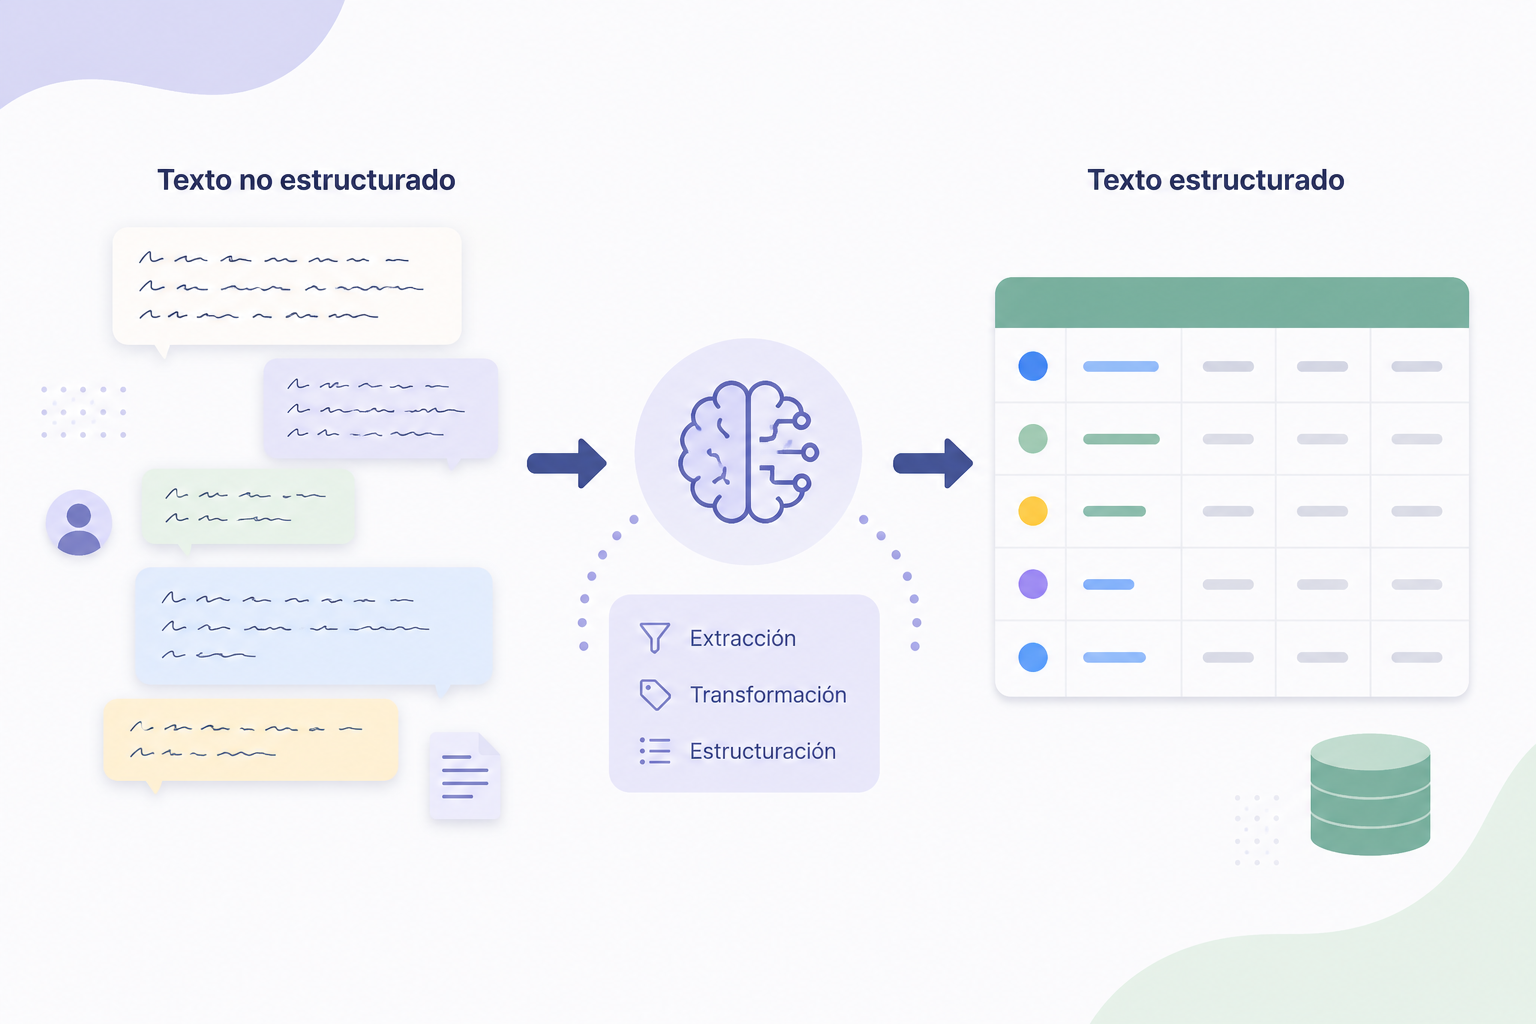

Uno de los grandes desafíos de trabajar con datos en salud es su estructura. Al intentar analizar historias clínicas nos encontraremos usualmente con datos no estructurados, los cuales consisten en un texto, de longitud variable, que incorpora información sobre el paciente y al consulta médica y el orden de la misma depende exclusivamente de como fue completada esta ficha. Para poder trabajar con estos datos necesitamos obtener información clave de cada texto, para luego poder analizar, clasificar, detectar patrones, entre otras cosas.

## Descripción de la base

Para esta clase trabajaremos con una base disponible pública en github: https://github.com/PlanTL-GOB-ES/SPACCC_MEDDOCAN .

Este repositorio contiene un corpus sintético de casos clínicos enriquecido con expresiones de información médica protegida (PHI, por sus siglas en inglés), denominado corpus MEDDOCAN.

La colección final de 1000 casos clínicos que componen el corpus cuenta con alrededor de 33 mil oraciones, con un promedio de unas 33 oraciones por caso clínico. El corpus MEDDOCAN contiene alrededor de 495 mil palabras, con una media de 494 palabras por caso clínico, un poco menos que los registros del corpus longitudinal de anonimización de i2b2 (617 tokens por registro). El corpus MEDDOCAN se distribuye en texto plano con codificación UTF8, donde cada caso clínico se almacena en un único archivo de texto, y las anotaciones de PHI se publican en el popular formato BRAT, lo que facilita la visualización de los resultados.El corpus SPACCC se creó tras recopilar 1000 casos clínicos de SciELO.

## Aplicación

Se puede aplicar NLP para detección de entidades clínicas, resumir información, predecir reingresos hospitalarios, realizar modelos de riesgo de mortalidad, sistemas de alertas tempranas, análisis de supervivencia y progresión, entre otras.

In [2]:
#Clonamos el repositorio con el cual trabajaremos
!git clone https://github.com/PlanTL-GOB-ES/SPACCC_MEDDOCAN.git

Cloning into 'SPACCC_MEDDOCAN'...
remote: Enumerating objects: 9847, done.
remote: Total 9847 (delta 0), reused 0 (delta 0), pack-reused 9847 (from 1)
Receiving objects: 100% (9847/9847), 11.30 MiB | 15.88 MiB/s, done.
Resolving deltas: 100% (30/30), done.


In [3]:
import os
ruta = "SPACCC_MEDDOCAN/corpus/dev/brat"
archivos = os.listdir(ruta)
print(archivos)

['S0365-66912012000200005-1.ann', 'S0004-06142006000700012-1.txt', 'S1130-05582014000300006-1.ann', 'S0004-06142009000500013-1.txt', 'S0004-06142008000300012-1.txt', 'S0212-16112014000200032-3.txt', 'S0004-06142009000100013-1.ann', 'S1137-66272016000200013-1.txt', 'S1130-01082005001000014-1.ann', 'S1130-05582003000600004-1.ann', 'S0004-06142008000100008-1.ann', 'S0210-48062006000300015-1.ann', 'S0004-06142008000100011-1.ann', 'S1137-66272014000300017-1.txt', 'S2254-28842014000300010-1.txt', 'S2254-28842014000300010-1.ann', 'S0376-78922016000200011-1.ann', 'S0365-66912008001000010-1.txt', 'S1135-76062009000200005-1.ann', 'S1130-05582015000100004-1.txt', 'S0211-69952015000500015-2.txt', 'S0212-16112013000300055-1.ann', 'S0365-66912006001200009-1.ann', 'S0365-66912006001200010-1.txt', 'S0212-16112012000600045-1.txt', 'S0212-16112006000100018-1.ann', 'S0211-57352013000300012-1.txt', 'S1130-01082009000300015-1.ann', 'S1130-01082008000100009-1.ann', 'S0465-546X2008000200010-1.ann', 'S1889-83

In [4]:
#Aquí podemos buscar un archivo y observar como se ve su estructura
with open(f"{ruta}/S0004-06142006000500012-1.txt", "r", encoding="utf-8") as f:
    contenido = f.read()
print(contenido)

Datos del paciente.
Nombre:  Pedro.
Apellidos: De Miguel Rivera.
NHC: 2569870.
Domicilio: Calle Carmen Romero, 23, 1D.
Localidad/ Provincia: Madrid.
CP: 28035.
Datos asistenciales.
Fecha de nacimiento: 10/10/1963.
País: España.
Edad: 53 años Sexo: H.
Fecha de Ingreso: 17/06/2016.
Médico: Estefanía Romero Selas  NºCol: 28 28 20943.
Informe clínico del paciente: varón de 53 años sin antecedentes de interés que ingresa procedente de urgencias con un cuadro de tromboembolismo pulmonar.
Ante la sospecha de neoplasia oculta y la presencia de hematuria no evidenciada previamente se procede a la realización de Ecografía abdominal donde se evidencia una masa renal derecha y se completa el estudio con TAC y RM..
Ambos estudios confirman la presencia de una tumoración heterogénea que infiltra los dos tercios inferiores del riñón derecho de aproximadamente 10x10 cms. con afectación del seno e hilio renal objetivándose también trombosis tumoral de la vena renal derecha y cava infrahepática. No se e

In [5]:
with open(f"{ruta}/S0004-06142006000600012-1.txt", "r", encoding="utf-8") as f:
    contenido = f.read()
print(contenido)

Datos del paciente.
Nombre:  Mariano.
Apellidos: Ramos Baez.
NHC: 2594890.
NASS: 47 39047534 02.
Domicilio: Av. Pedro Rubio, 36.
Localidad/ Provincia: Madrid.
CP: 28319.
Datos asistenciales.
Fecha de nacimiento: 13/09/1955.
País: España.
Edad: 62 años Sexo: H.
Fecha de Ingreso: 23/07/2017.
Médico:  NºCol: 28 28.
Informe clínico del paciente: Paciente de 62 años de edad,consulta por presentar dolor en hemiescroto derecho de tres meses de evolución, al examen físico se constata varicocele derecho grado IV, palpándose además voluminosa masa a nivel del área renal derecha. Se realiza ecografía abdominal que informa masa heterogénea de 10 cm. aproximadamente en riñón derecho, riñón izquierdo sin hallazgos patológicos. Se complementa con tomografía axial computada de abdomen y pelvis con contraste endovenoso donde se evidencia una formación renal derecha heterogénea de 110 x 120 mm de diámetro, no se observan adenomegalias retroperitoneales. Difícil evaluación del pedículo renal derecho.
Se 

In [6]:
#Aquí veremos los primeros 200 caracteres de cada uno de los archivos.
for nombre in os.listdir(ruta):
    if nombre.endswith(".txt"):
        with open(os.path.join(ruta, nombre), "r", encoding="utf-8") as f:
            texto = f.read()
        print(f"--- {nombre} ---")
        print(texto[:200])

--- S0004-06142006000700012-1.txt ---
Datos del paciente.
Nombre:  Carolina.
Apellidos: Ordoñez Julve.
NHC: 3598742.
NASS: 84 37283957 33.
Domicilio:  Av. de los Pajaros,18.
Localidad/ Provincia: Madrid.
CP: 28006.
Datos asistenciales.
Fe
--- S0004-06142009000500013-1.txt ---
Datos del paciente.
Nombre:  Elena.
Apellidos: Rivera Martinez.
NHC: 7809456.
NASS: 84 29487573 93.
Domicilio: Calle Finisterra, 18.
Localidad/ Provincia: Madrid.
CP: 28029.
Datos asistenciales.
Fecha
--- S0004-06142008000300012-1.txt ---
Datos del paciente.
Nombre:  Rocio.
Apellidos: Diez Navarro.
NHC: 2498674.
Domicilio: Av. Ginzo De Lima, 13.
Localidad/ Provincia: Madrid.
CP: 28029.
Datos asistenciales.
Fecha de nacimiento: 04/06/19
--- S0212-16112014000200032-3.txt ---
Nombre:  Alejandro.
Apellidos: Gutierrez Ramos.
NASS: 69 74381545 11.
Domicilio: Av. San Francisco Javier, 16, 3G .
Localidad/ Provincia: Sevilla.
CP: 41005.
NHC: 7412596.
Datos asistenciales.
Fecha d
--- S1137-66272016000200013-1.txt ---
Datos 

In [8]:
import os
import re
import pandas as pd

# ── 1. Cargar archivos ──────────────────────────────────────────────────────
ruta = "SPACCC_MEDDOCAN/corpus/dev/brat"
registros = {}
for nombre in os.listdir(ruta):
    if nombre.endswith(".txt"):
        with open(os.path.join(ruta, nombre), "r", encoding="utf-8") as f:
            registros[nombre] = f.read()

# ── 2. Patrones: datos del paciente ────────────────────────────────────────
patrones_paciente = {
    "nombre":    r"Nombre\s*:\s*(.+?)(?:\.|Apellidos)",
    "apellidos": r"Apellidos\s*:\s*(.+?)(?:\.|NHC)",
    "nhc":       r"NHC\s*:\s*([\w/]+)",
    "nass":      r"NASS\s*:\s*([\d\s]+?)(?:\.|Domicilio)",
    "domicilio": r"Domicilio\s*:\s*(.+?)(?:\.|Localidad)",
    "localidad": r"Localidad[/\s]*Provincia\s*:\s*(.+?)(?:\.|CP)",
    "cp":        r"CP\s*:\s*(\d+)",
    "fecha_nac": r"Fecha de nacimiento\s*:\s*([\d/]+)",
    "fecha_ing": r"Fecha de ingreso\s*:\s*([\d/]+)",
    "medico":    r"M[eé]dico\s*:\s*(.+?)(?:\.|$)",
    "edad":      r"Edad\s*:\s*(\d+)\s*(?:años|a[ñn]os)?",
    "sexo":      r"Sexo\s*:\s*([A-Za-zMmHhFf]\.?)",
}

# ── 3. Patrones: cuerpo clínico ────────────────────────────────────────────
# Primero separamos el bloque clínico del bloque de datos del paciente
patron_bloque_clinico = r"Datos asistenciales\.?(.*)"

patrones_clinicos = {
    # Campos con fecha que suelen aparecer al inicio
    "fecha_nacimiento_cli": r"Fecha de nacimiento\s*:\s*([\d/]+)",
    "fecha_ingreso_cli":    r"Fecha de ingreso\s*:\s*([\d/]+)",
    "fecha_alta":           r"Fecha de alta\s*:\s*([\d/]+)",

    # Episodio y motivo
    "motivo_consulta": r"Motivo de (?:consulta|ingreso)\s*[:.]?\s*(.+?)(?:\.|Antecedentes|Historia|Exploración|$)",
    "antecedentes":    r"Antecedentes(?:[^:]*)\s*[:.]?\s*(.+?)(?:\.|Exploración|Historia|Enfermedad|Pruebas|$)",
    "enfermedad_actual": r"(?:Enfermedad|Historia cl[ií]nica)\s*[:.]?\s*(.+?)(?:\.|Exploración|Pruebas|Antecedentes|$)",

    # Exploración y pruebas
    "exploracion":     r"Exploración(?:[^:]*)\s*[:.]?\s*(.+?)(?:\.|Pruebas|Diagnóstico|Tratamiento|$)",
    "pruebas_comp":    r"Pruebas complementarias\s*[:.]?\s*(.+?)(?:\.|Diagnóstico|Tratamiento|Evolución|$)",

    # Diagnóstico y tratamiento
    "diagnostico":     r"Diagn[oó]stico(?:[^:]*)\s*[:.]?\s*(.+?)(?:\.|Tratamiento|Evolución|$)",
    "tratamiento":     r"Tratamiento\s*[:.]?\s*(.+?)(?:\.|Evolución|Remitido|$)",
    "evolucion":       r"Evoluci[oó]n\s*[:.]?\s*(.+?)(?:\.|Remitido|$)",
}

# ── 4. Extracción ──────────────────────────────────────────────────────────
def extraer_campos(texto):
    fila = {}

    # Texto completo
    fila["texto_completo"] = texto.strip()

    # Datos del paciente
    for campo, patron in patrones_paciente.items():
        match = re.search(patron, texto, re.IGNORECASE | re.DOTALL)
        fila[campo] = match.group(1).strip() if match else None

    # Aislar bloque clínico (todo lo que viene después de "Datos asistenciales")
    match_bloque = re.search(patron_bloque_clinico, texto, re.IGNORECASE | re.DOTALL)
    bloque_clinico = match_bloque.group(1).strip() if match_bloque else ""
    fila["bloque_clinico"] = bloque_clinico  # columna con el texto clínico crudo

    # Campos dentro del bloque clínico
    for campo, patron in patrones_clinicos.items():
        match = re.search(patron, bloque_clinico, re.IGNORECASE | re.DOTALL)
        fila[campo] = match.group(1).strip() if match else None

    return fila

# ── 5. Construir DataFrame ─────────────────────────────────────────────────
filas = []
for nombre_archivo, texto in registros.items():
    fila = extraer_campos(texto)
    fila["archivo"] = nombre_archivo
    filas.append(fila)

columnas = (
    ["archivo", "texto_completo", "bloque_clinico"]
    + list(patrones_paciente.keys())
    + list(patrones_clinicos.keys())
)
df = pd.DataFrame(filas, columns=columnas)

# ── 6. Limpieza ────────────────────────────────────────────────────────────
df = df.apply(lambda col: col.str.strip() if col.dtype == "object" else col)

# ── 7. Exportar (opcional) ─────────────────────────────────────────────────
df.to_csv("historias_clinicas.csv", index=False, encoding="utf-8-sig")

print(f"Registros procesados: {len(df)}")
print(f"Columnas: {list(df.columns)}")
df.head()

Registros procesados: 250
Columnas: ['archivo', 'texto_completo', 'bloque_clinico', 'nombre', 'apellidos', 'nhc', 'nass', 'domicilio', 'localidad', 'cp', 'fecha_nac', 'fecha_ing', 'medico', 'edad', 'sexo', 'fecha_nacimiento_cli', 'fecha_ingreso_cli', 'fecha_alta', 'motivo_consulta', 'antecedentes', 'enfermedad_actual', 'exploracion', 'pruebas_comp', 'diagnostico', 'tratamiento', 'evolucion']


,archivo,texto_completo,bloque_clinico,nombre,apellidos,nhc,nass,domicilio,localidad,cp,...,fecha_ingreso_cli,fecha_alta,motivo_consulta,antecedentes,enfermedad_actual,exploracion,pruebas_comp,diagnostico,tratamiento,evolucion
0,S0004-06142006000700012-1.txt,Datos del paciente.\nNombre: Carolina.\nApell...,Fecha de nacimiento: 04/7/1952.\nPaís: España....,Carolina,Ordoñez Julve,3598742,84 37283957 33,Av,Madrid,28006,...,10/01/2016,None,None,masa en el polo superior del riñón izquierdo c...,None,None,None,masa en el polo superior del riñón izquierdo c...,con albendazol 400 mg cada 12 horas durante un...,"postoperatoria fue favorable, instaurándose tr..."
1,S0004-06142009000500013-1.txt,Datos del paciente.\nNombre: Elena.\nApellido...,Fecha de nacimiento: 19/10/1951.\nPaís: España...,Elena,Rivera Martinez,7809456,84 29487573 93,"Calle Finisterra, 18",Madrid,28029,...,14/04/2014,None,None,Dr,None,None,None,Dr,None,", con micosis oral y franco deterioro del esta..."
2,S0004-06142008000300012-1.txt,Datos del paciente.\nNombre: Rocio.\nApellido...,Fecha de nacimiento: 04/06/1977.\nPaís: España...,Rocio,Diez Navarro,2498674,None,Av,Madrid,28029,...,12/06/2018,None,None,"146 U/L, GPT: 171 U/L)",None,"146 U/L, GPT: 171 U/L)",None,"hepatomegalia, aumento de calibre de vena port...",None,"junto con náuseas, vómitos biliosos y mal esta..."
3,S0212-16112014000200032-3.txt,Nombre: Alejandro.\nApellidos: Gutierrez Ramo...,Fecha de nacimiento: 15/05/1937.\nPaís: España...,Alejandro,Gutierrez Ramos,7412596,69 74381545 11,Av,Sevilla,41005,...,15/11/2010,None,None,None,None,None,None,None,con quimioterapia y radioterapia hasta hacía 3...,None
4,S1137-66272016000200013-1.txt,Datos del paciente.\nNombre: Felipe.\nApellido...,Fecha de nacimiento: 28/02/1962.\nPaís: España...,Felipe,Rianxo Paz,3827464,48 57613958 03,"Plaza de Verín, 4, 3, B",A Coruña,15238,...,13/11/2016,None,None,A la,sistémica relacionada con IgG4,A la exploración presentaba dolor en hipocondr...,Analíticamente presentaba leucocitosis con neu...,None,antibiótico endovenoso la paciente se tornó as...,", sin fiebre ni sensación distérmica"


In [9]:
#Aquí podemos corroborar un poco nuestros datos, capturó el sexo de las personas?
df.sexo.value_counts()

,count
sexo,
H.,140
M.,88
F,9
H,3
F.,3
V,2
M,2


In [10]:
#Una opción ante estos datos en unificar criterios si tenemos la información que corresponde
def normalizar_sexo(valor):
    if not valor:
        return None
    v = valor.strip().upper().strip(".")
    if v in ["H", "HOMBRE", "MASCULINO", "V"]:
        return "M"
    if v in ["F", "MU", "MUJER", "FEMENINO"]:
        return "F"
    return valor

df["sexo"] = df["sexo"].apply(normalizar_sexo)
df.sexo.value_counts()

,count
sexo,
M,147
M.,88
F,12


## Preprocesamiento de texto

Para poder continuar trabajando con nuestra base es importante que apliquemos una "limpieza de ruido" para que sea más fácil de manipular.


## Conocemos algunas características básicas de la base

In [11]:
#Dimensiones
df.shape

(250, 26)

In [12]:
#Nombre de columnas
df.columns

Index(['archivo', 'texto_completo', 'bloque_clinico', 'nombre', 'apellidos',
       'nhc', 'nass', 'domicilio', 'localidad', 'cp', 'fecha_nac', 'fecha_ing',
       'medico', 'edad', 'sexo', 'fecha_nacimiento_cli', 'fecha_ingreso_cli',
       'fecha_alta', 'motivo_consulta', 'antecedentes', 'enfermedad_actual',
       'exploracion', 'pruebas_comp', 'diagnostico', 'tratamiento',
       'evolucion'],
      dtype='object')

In [13]:
#Vista previa de primeras filas
df.head()

,archivo,texto_completo,bloque_clinico,nombre,apellidos,nhc,nass,domicilio,localidad,cp,...,fecha_ingreso_cli,fecha_alta,motivo_consulta,antecedentes,enfermedad_actual,exploracion,pruebas_comp,diagnostico,tratamiento,evolucion
0,S0004-06142006000700012-1.txt,Datos del paciente.\nNombre: Carolina.\nApell...,Fecha de nacimiento: 04/7/1952.\nPaís: España....,Carolina,Ordoñez Julve,3598742,84 37283957 33,Av,Madrid,28006,...,10/01/2016,None,None,masa en el polo superior del riñón izquierdo c...,None,None,None,masa en el polo superior del riñón izquierdo c...,con albendazol 400 mg cada 12 horas durante un...,"postoperatoria fue favorable, instaurándose tr..."
1,S0004-06142009000500013-1.txt,Datos del paciente.\nNombre: Elena.\nApellido...,Fecha de nacimiento: 19/10/1951.\nPaís: España...,Elena,Rivera Martinez,7809456,84 29487573 93,"Calle Finisterra, 18",Madrid,28029,...,14/04/2014,None,None,Dr,None,None,None,Dr,None,", con micosis oral y franco deterioro del esta..."
2,S0004-06142008000300012-1.txt,Datos del paciente.\nNombre: Rocio.\nApellido...,Fecha de nacimiento: 04/06/1977.\nPaís: España...,Rocio,Diez Navarro,2498674,None,Av,Madrid,28029,...,12/06/2018,None,None,"146 U/L, GPT: 171 U/L)",None,"146 U/L, GPT: 171 U/L)",None,"hepatomegalia, aumento de calibre de vena port...",None,"junto con náuseas, vómitos biliosos y mal esta..."
3,S0212-16112014000200032-3.txt,Nombre: Alejandro.\nApellidos: Gutierrez Ramo...,Fecha de nacimiento: 15/05/1937.\nPaís: España...,Alejandro,Gutierrez Ramos,7412596,69 74381545 11,Av,Sevilla,41005,...,15/11/2010,None,None,None,None,None,None,None,con quimioterapia y radioterapia hasta hacía 3...,None
4,S1137-66272016000200013-1.txt,Datos del paciente.\nNombre: Felipe.\nApellido...,Fecha de nacimiento: 28/02/1962.\nPaís: España...,Felipe,Rianxo Paz,3827464,48 57613958 03,"Plaza de Verín, 4, 3, B",A Coruña,15238,...,13/11/2016,None,None,A la,sistémica relacionada con IgG4,A la exploración presentaba dolor en hipocondr...,Analíticamente presentaba leucocitosis con neu...,None,antibiótico endovenoso la paciente se tornó as...,", sin fiebre ni sensación distérmica"


## Normalizar el texto

Para normalizar el texto podemos pasar todo a minúscula, así como eliminar los caracteres especiales. En este sentido, ¿cuáles consideramos que serían caracteres especiales en nuestro dataset? ¿Cuáles no son informativos en los siguientes pasos de análisis?


In [18]:
# Permitimos explícitamente el código remoto para descargar el dataset antiguo
from datasets import load_dataset
ds = load_dataset("fvillena/spanish_diagnostics", trust_remote_code=True)

`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'fvillena/spanish_diagnostics' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.
ERROR:datasets.load:`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'fvillena/spanish_diagnostics' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


RuntimeError: Dataset scripts are no longer supported, but found spanish_diagnostics.py

In [23]:
import pandas as pd

# Usamos las URLs de los archivos Parquet autoconvertidos oficiales de Hugging Face que sí están activos y disponibles
train_parquet_url = "https://huggingface.co/datasets/fvillena/spanish_diagnostics/resolve/refs%2Fconvert%2Fparquet/default/train/0000.parquet"
test_parquet_url = "https://huggingface.co/datasets/fvillena/spanish_diagnostics/resolve/refs%2Fconvert%2Fparquet/default/test/0000.parquet"

class DatasetWrapper:
    def __init__(self, df):
        self.df = df
    def to_pandas(self):
        return self.df

# Cargamos los DataFrames utilizando pandas directamente desde los parquets del hub
df_train = pd.read_parquet(train_parquet_url)
df_test = pd.read_parquet(test_parquet_url)

ds = {
    "train": DatasetWrapper(df_train),
    "test": DatasetWrapper(df_test)
}

print("¡Dataset cargado con éxito!")
print(f"Registros de entrenamiento: {len(df_train)}")

¡Dataset cargado con éxito!
Registros de entrenamiento: 70000


In [24]:
import pandas as pd

df = pd.concat([
    ds["train"].to_pandas().assign(split="train"),
    ds["test"].to_pandas().assign(split="test")
], ignore_index=True)

In [25]:
pd.set_option('display.max_colwidth', None)
df['text']

,text
0,- ANOMALÍAS DENTOFACIALES (INCLUSO LA MALOCLUSIÓN)\n\n\n DISCREPANCIA DENTOMAXILAR
1,OBTRUCCION FOSA NASAL DERECHA
2,Perturbación de la actividad y de la atención Trastorno defícit atencional
3,M7 PROLAPSO VAGINAL PARED ANTERIOR G11 G 111 ALGIA PELVICA HTA CRONICA
4,"PIEZA 3 CARIES DENTINARIA PROFUNDA PROXIMA A CAMARA PULPAR, EVALUAR POR ESPECIALIDAD"
...,...
99995,Ecografía con signos de esteatosis hepática leve y colelitiasis crónica litiasica
99996,vejiga neurogenica nueva sic 28062015 estructura proposicional fimosis
99997,"PIEZA 1 Y 16 CARIADAS, ERUPCIONADAS. PIEZA 17 Y 32 SEMIERUPCIONADAS. SOLICITO POSIBLIDAD DE EXODONCIAS."
99998,PIEZA 3.8 SEMIERUPCIONADAS PIEZA 4.8 RETENIDA E OMPACTADA EN 4.7


Eliminamos elementos ruidosos






In [27]:
import unicodedata

def limpiar_texto(texto):
    # Normalizar unicode (ej: ã¡ → á, caracteres raros de encoding)
    texto = unicodedata.normalize("NFKC", texto) #Normalization Form Compatibility Composition

    # Colapsar múltiples espacios en uno solo
    texto = re.sub(r" {2,}", " ", texto)

    # Colapsar múltiples saltos de línea
    texto = re.sub(r"\n{2,}", "\n", texto)

    # Eliminar espacios antes de puntuación
    texto = re.sub(r" ([.,;:])", r"\1", texto)

    # Unificar comillas y guiones raros
    texto = texto.replace("\u201c", '"').replace("\u201d", '"')  # " "
    texto = texto.replace("\u2013", "-").replace("\u2014", "-")  # – —

    # Eliminar caracteres de control (excepto \n y \t)
    texto = re.sub(r"[^\S\n\t ]+", " ", texto)

    return texto.strip()

# Aplicar sobre todos los textos antes de extraer campos
registros = {nombre: limpiar_texto(texto) for nombre, texto in registros.items()}

## Vemos como queda nuestro texto limpio.


In [28]:
registros['S1699-695X2016000200009-1.txt']

'Datos del paciente.\nNombre: Martin.\nApellidos: Castillo Puebla.\nNHC: 3089257.\nDomicilio: Calle Antonio González Echarte, 1, 3A.\nLocalidad/ Provincia: Madrid.\nCP: 28029.\nDatos asistenciales.\nFecha de nacimiento: 05/04/2008.\nPaís: España.\nEdad: 10 años Sexo: Varón.\nFecha de Ingreso: 31/05/2018.\nMédico: Ruth Bravo Lizcano NoCol: 28 31 23689.\nHistoria Actual: varón de 10 años sin antecedentes de interés, con gonalgia bilateral, dorsalgia y lumbalgia tras caída de una bicicleta hace 4 días. A la exploración presentaba una movilidad activa y pasiva conservada con dolor en ambos miembros inferiores (MMII). No se observaron datos de fracturas ni alteraciones neurológicas. Se pautó reposo deportivo, frío local y tratamiento antiinflamatorio. A las 48 horas, el paciente acude nuevamente por persistencia del dolor, pérdida de fuerza, parestesias en MMII, dificultad para incorporarse y deambular e incontinencia urinaria. \nExploración física: La exploración física reveló una disminuc

In [29]:
#Aplicamos la estructura a los textos ya limpios

import os
import re
import unicodedata
import pandas as pd

# ── 1. Cargar archivos ──────────────────────────────────────────────────────
ruta = "SPACCC_MEDDOCAN/corpus/dev/brat"
registros = {}
for nombre in os.listdir(ruta):
    if nombre.endswith(".txt"):
        with open(os.path.join(ruta, nombre), "r", encoding="utf-8") as f:
            registros[nombre] = f.read()

# ── 2. Patrones: datos del paciente ────────────────────────────────────────
patrones_paciente = {
    "nombre":    r"Nombre\s*:\s*(.+?)(?:\.|Apellidos)",
    "apellidos": r"Apellidos\s*:\s*(.+?)(?:\.|NHC|CIPA)",
    "nhc":       r"(?:NHC|CIPA[^:]*)\s*:\s*([\w/\-]+)",
    "nass":      r"NASS\s*:\s*([\d\s]+?)(?:\.|Domicilio)",
    "domicilio": r"Domicilio\s*:\s*(.+?)(?:\.|Localidad)",
    "localidad": r"Localidad[/\s]*Provincia\s*:\s*(.+?)(?:\.|CP)",
    "cp":        r"CP\s*:\s*(\d+)",
    "pais":      r"Pa[ií]s(?:[^:]*)\s*:\s*(.+?)(?:\.|Edad|Fecha)",
    "fecha_nac": r"Fecha de nacimiento\s*:\s*([\d/]+)",
    "edad":      r"Edad\s*:\s*(\d+)\s*(?:años|meses)?",
    "unidad_edad": r"Edad\s*:\s*\d+\s*(años|meses)",
    "sexo":      r"Sexo\s*:\s*([A-Za-záéíóúÁÉÍÓÚ]+\.?)",
    "fecha_ing": r"Fecha de [Ii]ngreso\s*:\s*([\d/]+)",
    "servicio":  r"(?:Servicio|Especialidad)\s*:\s*(.+?)(?:\.|Médico|Episodio)",
    "medico":    r"M[eé]dico\s*:\s*(.+?)(?:NoCol|\.|$)",
}

# ── 3. Patrones: cuerpo clínico ────────────────────────────────────────────
patron_bloque_clinico = r"Datos asistenciales\.?(.*)"

patrones_clinicos = {
    "motivo_consulta":  r"Motivo de (?:consulta|ingreso)\s*[:.]?\s*(.+?)(?:\n[A-ZÁÉÍÓÚ]|\.|Antecedentes|Historia|Exploración|$)",
    "antecedentes":     r"Antecedentes(?:[^:]*)\s*[:.]?\s*(.+?)(?:\n[A-ZÁÉÍÓÚ]|\.|Exploración|Historia|Enfermedad|Pruebas|$)",
    "historia_actual":  r"Historia(?:\s+[Aa]ctual|[^:]*)\s*[:.]?\s*(.+?)(?:\n[A-ZÁÉÍÓÚ]|\.|Exploración|Pruebas|Antecedentes|$)",
    "informe_clinico":  r"Informe cl[ií]nico del paciente\s*[:.]?\s*(.+?)(?:\n[A-ZÁÉÍÓÚ][^a-z]|\.|Exploración|Pruebas|Remitido|Responsable|$)",
    "exploracion":      r"Exploración(?:[^:]*)\s*[:.]?\s*(.+?)(?:\n[A-ZÁÉÍÓÚ]|\.|Pruebas|Diagnóstico|Tratamiento|$)",
    "pruebas_comp":     r"(?:Pruebas complementarias|Resumen de pruebas[^:]*)\s*[:.]?\s*(.+?)(?:\n[A-ZÁÉÍÓÚ]|\.|Diagnóstico|Tratamiento|Evolución|$)",
    "diagnostico":      r"Diagn[oó]stico(?:[^:]*)\s*[:.]?\s*(.+?)(?:\n[A-ZÁÉÍÓÚ]|\.|Tratamiento|Evolución|Remitido|$)",
    "tratamiento":      r"Tratamiento\s*[:.]?\s*(.+?)(?:\n[A-ZÁÉÍÓÚ]|\.|Evolución|Remitido|$)",
    "evolucion":        r"Evoluci[oó]n(?:[^:]*)\s*[:.]?\s*(.+?)(?:\n[A-ZÁÉÍÓÚ]|\.|Remitido|Responsable|$)",
    "remitido_por":     r"(?:Remitido por|Responsable cl[ií]nico|Direcci[oó]n para correspondencia)\s*[:.]?\s*(.+?)$",
}

# ── 4. Normalización ───────────────────────────────────────────────────────
def normalizar_sexo(valor):
    if not valor:
        return None
    v = valor.strip().upper().strip(".")
    if v in ["H", "HOMBRE", "MASCULINO", "VARON", "VARÓN", "V"]:
        return "M"
    if v in ["F", "M", "MU", "MUJER", "FEMENINO", "FEMININO"]:
        return "F"
    return valor

# ── 5. Extracción ──────────────────────────────────────────────────────────
def extraer_campos(texto):
    fila = {}
    fila["texto_completo"] = texto.strip()

    for campo, patron in patrones_paciente.items():
        match = re.search(patron, texto, re.IGNORECASE | re.DOTALL)
        fila[campo] = match.group(1).strip() if match else None

    fila["sexo"] = normalizar_sexo(fila.get("sexo"))

    match_bloque = re.search(patron_bloque_clinico, texto, re.IGNORECASE | re.DOTALL)
    bloque_clinico = match_bloque.group(1).strip() if match_bloque else texto
    fila["bloque_clinico"] = bloque_clinico

    for campo, patron in patrones_clinicos.items():
        match = re.search(patron, bloque_clinico, re.IGNORECASE | re.DOTALL)
        fila[campo] = match.group(1).strip() if match else None

    return fila

# ── 6. Construir DataFrame ─────────────────────────────────────────────────
filas = []
for nombre_archivo, texto in registros.items():
    fila = extraer_campos(texto)
    fila["archivo"] = nombre_archivo
    filas.append(fila)

columnas = (
    ["archivo", "texto_completo", "bloque_clinico"]
    + list(patrones_paciente.keys())
    + list(patrones_clinicos.keys())
)
df = pd.DataFrame(filas, columns=columnas)
df = df.apply(lambda col: col.str.strip() if col.dtype == "object" else col)

# ── 7. Cobertura por columna ───────────────────────────────────────────────
cobertura = df.notna().mean().mul(100).round(1).sort_values(ascending=False)
print("Cobertura por campo (%):\n", cobertura.to_string())

# ── 8. Exportar ────────────────────────────────────────────────────────────
df.to_csv("historias_clinicas.csv", index=False, encoding="utf-8-sig")
print(f"\nRegistros procesados: {len(df)}")
df.head()

Cobertura por campo (%):
 archivo            100.0
texto_completo     100.0
bloque_clinico     100.0
nombre             100.0
apellidos          100.0
domicilio          100.0
pais               100.0
localidad          100.0
fecha_nac          100.0
fecha_ing          100.0
medico             100.0
edad                99.6
remitido_por        99.6
nhc                 99.2
sexo                98.8
cp                  97.6
unidad_edad         92.8
nass                76.0
tratamiento         72.8
evolucion           64.8
antecedentes        61.6
exploracion         58.4
informe_clinico     54.0
diagnostico         48.8
historia_actual     44.8
servicio            35.2
pruebas_comp        29.6
motivo_consulta     12.0

Registros procesados: 250


archivo  \
0  S0004-06142006000700012-1.txt   
1  S0004-06142009000500013-1.txt   
2  S0004-06142008000300012-1.txt   
3  S0212-16112014000200032-3.txt   
4  S1137-66272016000200013-1.txt   

                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                

## Tokenización

Consiste en dividir un bloque de texto continuo (como un párrafo o una oración) en unidades más pequeñas que se denominarán tokens. Los tokens suelen ser palabras sueltas, números o signos de puntuación.

Los modelos de Machine Learning y Deep Learning no pueden procesar texto en bruto; solo entienden números. La tokenización es el puente: Al separar el texto en tokens, a cada palabra única se le asigna un número identificador (ID). Esto permite transformar la historia clínica en un vector numérico (como los word embeddings) para que un algoritmo pueda buscar patrones, clasificar el texto o predecir diagnósticos.

Existen distintos tipos de tokenización, veremos con ejemplos los más utilizados:

In [30]:
#Vamos a utilizar la siguiente libreria nltk
import nltk
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

**Tokenización por palabras (Word tokenization)**

Es la más común. Corta el texto cada vez que encuentra un espacio en blanco.

In [31]:
from nltk.tokenize import word_tokenize
texto = "El paciente ingresó con fiebre; se le recetó paracetamol."
word_tokenize(texto, language='spanish')

['El',
 'paciente',
 'ingresó',
 'con',
 'fiebre',
 ';',
 'se',
 'le',
 'recetó',
 'paracetamol',
 '.']

**Tokenización por oraciones (Sentence tokenization)**

Identifica los límites de las frases (puntos, signos de interrogación, exclamaciones) para separar un párrafo en enunciados completos.

In [32]:
from nltk.tokenize import sent_tokenize
texto_oraciones = "¡Atención! El quirófano número 3 está listo. Por favor, traslade al paciente de inmediato."
sent_tokenize(texto_oraciones, language='spanish')

['¡Atención!',
 'El quirófano número 3 está listo.',
 'Por favor, traslade al paciente de inmediato.']

**Tokenización por subpalabras (Subword tokenization)**

Es la técnica que usan modelos de lenguaje actuales (como BERT, GPT o Llama). Divide los términos complejos o poco comunes en fragmentos más pequeños (morfemas o sílabas de datos) para que el modelo nunca se tope con una palabra que "no conozca".

**La idea central**: en lugar de tener una entrada en el vocabulario para cada palabra posible del idioma (imposible, porque las palabras son infinitas), el modelo aprende un vocabulario de fragmentos frecuentes — prefijos, sufijos, raíces — y los combina.

¿Cómo se aprenden esos fragmentos? Algoritmos como BPE (Byte-Pair Encoding) o WordPiece analizan millones de textos y fusionan iterativamente los pares de caracteres que aparecen juntos con más frecuencia. Al final quedan unos 30.000–50.000 fragmentos que cubren prácticamente cualquier texto.


**Las ventajas concretas son tres:**
- Primero, el modelo nunca ve una palabra desconocida — si aparece un neologismo o un tecnicismo rarísimo, simplemente lo divide en pedazos que sí conoce.
- Segundo, palabras relacionadas comparten fragmentos (##tico en farmacéutico, terapéutico, anestésico), lo que ayuda al modelo a inferir relaciones semánticas casi de forma automática.
- Tercero, el vocabulario se mantiene manejable en tamaño, lo que hace que los modelos sean eficientes computacionalmente.

In [33]:
from transformers import AutoTokenizer

# Cargamos el tokenizador preentrenado para español (BETO)
tokenizer = AutoTokenizer.from_pretrained("dccuchile/bert-base-spanish-wwm-cased")

# Usamos palabras complejas o médicas que suelen dividirse
texto_subpalabras = "El tratamiento inmunoterapéutico fue administrado."

tokenizer.tokenize(texto_subpalabras)

# Nota: Los símbolos '##' indican que ese fragmento está pegado al anterior.

config.json:   0%|          | 0.00/648 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/364 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/242k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/480k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/134 [00:00<?, ?B/s]

['El',
 'tratamiento',
 'inmun',
 '##ote',
 '##ra',
 '##péu',
 '##tico',
 'fue',
 'administrado',
 '.']

## Eliminación de stopwords

Se trata del proceso de filtrar y remover del texto aquellas palabras muy comunes que no aportan un significado real o contexto temático al análisis (palabras vacías). En español, estas palabras suelen ser artículos (el, la, los), preposiciones (de, en, para), conjunciones (y, o, pero) o algunos pronombres. Al eliminarlas, reducimos drásticamente el tamaño del vocabulario y permitimos que los algoritmos de ML se concentren únicamente en las palabras importantes (sustantivos, verbos, adjetivos) que realmente definen el tema del texto.

### **NLTK**

In [34]:
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

# Descargar los recursos necesarios
nltk.download('stopwords')

# Cargar las stopwords de español
stop_words_nltk = set(stopwords.words('spanish'))
print("Stopwords en NLTK (ejemplo):", list(stop_words_nltk)[:20])

Stopwords en NLTK (ejemplo): ['éramos', 'estuvisteis', 'fuese', 'estaréis', 'estabais', 'tengan', 'vuestros', 'hubieron', 'fuisteis', 'estuviste', 'tendrías', 'algo', 'tengamos', 'sois', 'tendréis', 'fuiste', 'suya', 'estaba', 'tuviéramos', 'vosotras']


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [35]:
# CÓMO AGREGAR UNA NUEVA STOPWORD
stop_words_nltk.add('paciente') #agrego una palabra
#stop_words_nltk.update(['ingresó', 'doctor']) # para agregar varias
print("Stopwords en NLTK (ejemplo):", list(stop_words_nltk)[:20])

Stopwords en NLTK (ejemplo): ['éramos', 'estuvisteis', 'fuese', 'estaréis', 'estabais', 'tengan', 'vuestros', 'hubieron', 'fuisteis', 'estuviste', 'tendrías', 'algo', 'tengamos', 'sois', 'tendréis', 'fuiste', 'suya', 'estaba', 'tuviéramos', 'vosotras']


In [36]:
# 3. Filtrar un texto
texto = "El paciente ingresó por la tarde con dolor de cabeza intenso."
tokens = word_tokenize(texto.lower(), language='spanish') #primero tokenizamos

texto_filtrado = [word for word in tokens if word not in stop_words_nltk] #luego filtramos
print("Texto filtrado con NLTK:", texto_filtrado)
# 'paciente' e 'ingresó' habrán desaparecido por haberlas añadido.

Texto filtrado con NLTK: ['ingresó', 'tarde', 'dolor', 'cabeza', 'intenso', '.']


### Visualización de preprocesamiento eliminando stopwords

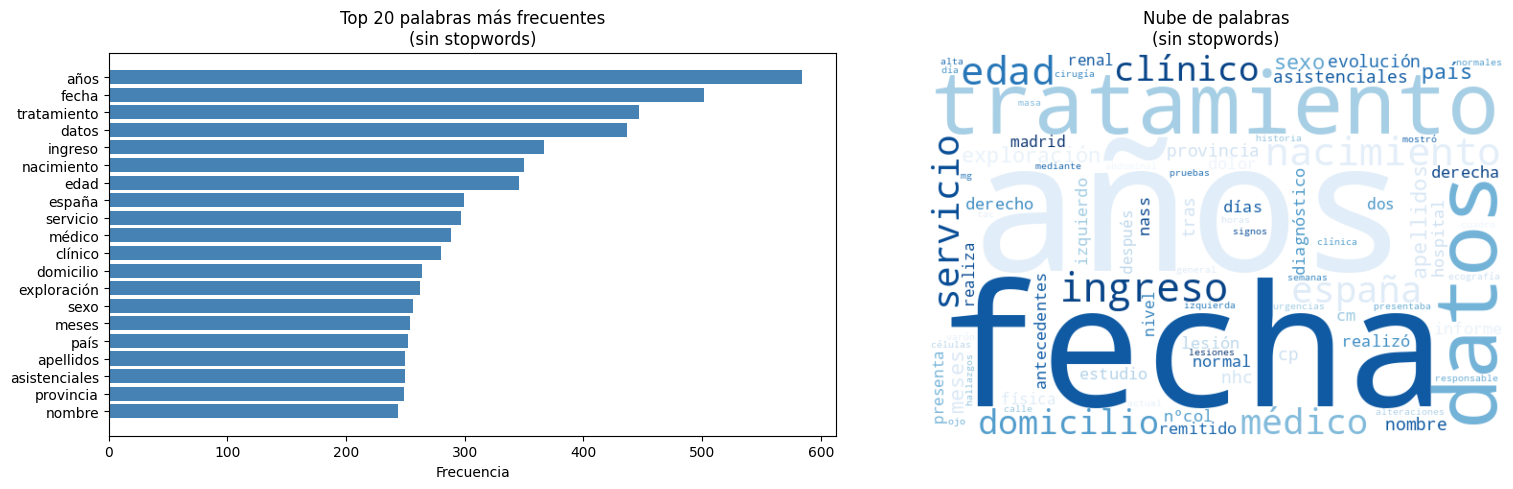

Total tokens antes del filtrado: 131111
Total tokens después del filtrado: 62772
Reducción: 52.1%


In [37]:
from collections import Counter
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from nltk.tokenize import word_tokenize

# Concatenamos todos los textos del dataframe (columna texto_completo o similar)
# Ajustá el nombre de la columna según tu df
texto_total = " ".join(df["texto_completo"].dropna().tolist()).lower()

# Tokenizamos y filtramos stopwords
tokens_total = word_tokenize(texto_total, language='spanish')
tokens_filtrados = [
    w for w in tokens_total
    if w.isalpha() and w not in stop_words_nltk
]

# ── Frecuencias ─────────────────────────────────────────────────────────────
frecuencias = Counter(tokens_filtrados)
mas_comunes = frecuencias.most_common(20)

palabras_freq, conteos = zip(*mas_comunes)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Gráfico de barras
axes[0].barh(palabras_freq[::-1], conteos[::-1], color="steelblue")
axes[0].set_title("Top 20 palabras más frecuentes\n(sin stopwords)")
axes[0].set_xlabel("Frecuencia")

# Nube de palabras
wc = WordCloud(
    width=600, height=400,
    background_color="white",
    colormap="Blues",
    max_words=80
).generate_from_frequencies(frecuencias)

axes[1].imshow(wc, interpolation="bilinear")
axes[1].axis("off")
axes[1].set_title("Nube de palabras\n(sin stopwords)")

plt.tight_layout()
plt.show()

print(f"Total tokens antes del filtrado: {len(tokens_total)}")
print(f"Total tokens después del filtrado: {len(tokens_filtrados)}")
print(f"Reducción: {100 - round(len(tokens_filtrados)/len(tokens_total)*100, 1)}%")

### **Spacy**

spaCy es una librería de Python para procesamiento de lenguaje natural (NLP), diseñada para ser rápida y lista para producción.
A diferencia de NLTK (más académica y modular), spaCy viene con todo integrado: cargás un modelo y ya podés hacer tokenización, etiquetado gramatical, reconocimiento de entidades, análisis de dependencias sintácticas, y más — todo en pocas líneas de código.

In [38]:
#Instalar este modelo si o si
!python -m spacy download es_core_news_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.9/12.9 MB 45.8 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('es_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [39]:
import spacy

# Cargar el modelo en español (asegúrate de tenerlo instalado: python -m spacy download es_core_news_sm)
nlp = spacy.load("es_core_news_sm")

# Obtener las stopwords actuales
stop_words_spacy = nlp.Defaults.stop_words

print("Stopwords en Spacy (ejemplo):", list(stop_words_spacy)[:20])

Stopwords en Spacy (ejemplo): ['puede', 'aquellas', 'despacio', 'ningunas', 'propias', 'aquí', 'ahi', 'eramos', 'hago', 'existen', 'pudo', 'después', 'mia', 'vuestros', 'sola', 'podria', 'dado', 'éste', 'saber', 'dicen']


In [ ]:
# CÓMO AGREGAR UNA NUEVA STOPWORD

nlp.Defaults.stop_words.add("paciente")
#nlp.Defaults.stop_words.update(["ingresó", "doctor"])

print("Stopwords en Spacy (ejemplo):", list(stop_words_spacy)[:20])

Stopwords en Spacy (ejemplo): ['aquellas', 'sobre', 'mucha', 'aqui', 'todo', 'podrían', 'señaló', 'saber', 'algunas', 'llegó', 'nosotras', 'habrá', 'manifestó', 'verdadero', 'alguno', 'donde', 'dejó', 'pueda', 'estuvo', 'habían']


In [40]:
# Filtrar un texto utilizando el pipeline de spaCy
texto = "El paciente ingresó por la tarde con dolor de cabeza intenso."
doc = nlp(texto.lower())

texto_filtrado = [token.text for token in doc if not token.is_stop and not token.is_punct]

print("Texto filtrado con spacy:", texto_filtrado)

Texto filtrado con spacy: ['paciente', 'ingresó', 'dolor', 'cabeza', 'intenso']


### Comparación NLTK vs spaCy sobre el mismo texto


A continuación se puede observar una comparación entre ambas librerías, cómo cada una realiza dos tareas fundamentales: la tokenización (separar en palabras) y el filtrado de stopwords (palabras vacías) en español.

In [41]:
import pandas as pd

texto_prueba = "El paciente ingresó por la tarde con dolor de cabeza intenso."

# NLTK
tokens_nltk = word_tokenize(texto_prueba.lower(), language='spanish')
resultado_nltk = [w for w in tokens_nltk if w not in stop_words_nltk and w.isalpha()]

# spaCy
doc_prueba = nlp(texto_prueba.lower())
resultado_spacy = [token.text for token in doc_prueba if not token.is_stop and token.is_alpha]

comparacion = pd.DataFrame({
    "NLTK":  pd.Series(resultado_nltk),
    "spaCy": pd.Series(resultado_spacy)
})

print("Texto original:", texto_prueba)
print()
print(comparacion.to_string(index=False))
print()
print("Nota: spaCy además realiza análisis morfológico y reconoce entidades,")
print("mientras que NLTK aplica una lista estática de stopwords.")

Texto original: El paciente ingresó por la tarde con dolor de cabeza intenso.

   NLTK    spaCy
ingresó paciente
  tarde  ingresó
  dolor    dolor
 cabeza   cabeza
intenso  intenso

Nota: spaCy además realiza análisis morfológico y reconoce entidades,
mientras que NLTK aplica una lista estática de stopwords.


1. La forma de filtrar las palabras vacías (stopwords)
- NLTK (Lista estática): Funciona como un buscador simple. Tiene una lista de palabras en un archivo de texto (como "el", "por", "la", "con") y simplemente hace un filtro directo: "Si la palabra de la frase está en mi lista, la borro". Es rápido, pero rígido.
- spaCy (Modelo estadístico/lingüístico): No solo usa una lista, sino que entiende el contexto gracias a que fue entrenado con millones de textos. Sabe si una palabra actúa como conector o si tiene un peso gramatical en esa oración específica.

## Lematización o Stemming

La lematización y el stemming son técnicas de normalización lingüística en el PLN. Ambas sirven para un mismo objetivo: reducir las palabras a su forma raíz para unificar el vocabulario, pero lo hacen mediante caminos completamente diferentes.

¿Qué es el **Stemming**? (Truncamiento)
El stemming es un método heurístico y rústico. Consiste en recortar el final de las palabras mediante reglas fijas para quedarse con la "raíz genética" o tallo (stem). No le importa la gramática ni el contexto; simplemente elimina sufijos, flexiones de género, número o conjugaciones verbales a la fuerza.


```
En el ejemplo: médico, médica, médicos y medicamento el stem sería medic
```

¿Qué es la **Lematización**? (Análisis lingüístico)
La lematización es un proceso mucho más avanzado linguisticamente. Utiliza un diccionario completo del idioma (vocabulario) y reglas morfológicas para encontrar el lema de una palabra, que es su forma base o la palabra tal cual aparecería como entrada en el diccionario de la Real Academia Española (RAE).


```
En el ejemplo : gatas y gatinos el lema sería gato.
En el ejemplo: estuve, estábamos, serán se transformará en los infinitivos estar y ser.
```



Este proceso es útil para reducir dimensionalidad, mejorar motores de búsqueda y realizar clustering de palabras, entre otras cosas.

In [42]:
from nltk.stem.snowball import SnowballStemmer

# Configurar el stemmer para el idioma español
stemmer = SnowballStemmer(language='spanish')

# Lista de palabras con variaciones de género, número y conjugaciones verbales
palabras = ["médicos", "médica", "medicamentos", "medicando", "computadoras", "computación", "corriendo", "corrió"]

print("--- EJEMPLO DE STEMMING (NLTK) ---")
for palabra in palabras:
    raiz = stemmer.stem(palabra)
    print(f"{palabra:15} ---> Raíz (Stem): {raiz}")

--- EJEMPLO DE STEMMING (NLTK) ---
médicos         ---> Raíz (Stem): medic
médica          ---> Raíz (Stem): medic
medicamentos    ---> Raíz (Stem): medicament
medicando       ---> Raíz (Stem): medic
computadoras    ---> Raíz (Stem): comput
computación     ---> Raíz (Stem): comput
corriendo       ---> Raíz (Stem): corr
corrió          ---> Raíz (Stem): corr


In [43]:
import spacy

# Cargar el modelo en español
nlp = spacy.load("es_core_news_sm")

# Un texto completo para que spaCy pueda entender el contexto de las palabras
texto = "Los pacientes estuvieron esperando a las médicas porque se sentían peor."

# Procesar el texto
doc = nlp(texto)

print("--- EJEMPLO DE LEMATIZACIÓN (spaCy) ---")
# Recorremos cada token (palabra) para extraer su texto original y su lema
for token in doc:
    # Ignoramos los signos de puntuación para limpiar la salida
    if not token.is_punct:
        print(f"{token.text:15} ---> Lema: {token.lemma_}")

--- EJEMPLO DE LEMATIZACIÓN (spaCy) ---
Los             ---> Lema: el
pacientes       ---> Lema: paciente
estuvieron      ---> Lema: estar
esperando       ---> Lema: esperar
a               ---> Lema: a
las             ---> Lema: el
médicas         ---> Lema: médica
porque          ---> Lema: porque
se              ---> Lema: él
sentían         ---> Lema: sentir
peor            ---> Lema: peor


### Stemming vs Lematización: comparación lado a lado

In [44]:
import pandas as pd
from nltk.stem.snowball import SnowballStemmer
import spacy

stemmer = SnowballStemmer(language='spanish')
nlp = spacy.load("es_core_news_sm")

palabras = [
    "pacientes", "hospitalizado", "corriendo", "médicos",
    "enfermedades", "tratamientos", "operaciones", "dolor"
]

filas = []
for palabra in palabras:
    stem = stemmer.stem(palabra)
    doc = nlp(palabra)
    lema = doc[0].lemma_
    filas.append({"Palabra original": palabra, "Stemming": stem, "Lematización": lema})

df_comp = pd.DataFrame(filas)
print(df_comp.to_string(index=False))
print()
print("Stemming: recorta la palabra mecánicamente (puede no ser una palabra real).")
print("Lematización: devuelve la forma canónica según gramática (siempre es una palabra válida).")

Palabra original   Stemming  Lematización
       pacientes    pacient      paciente
   hospitalizado hospitaliz hospitalizado
       corriendo       corr        correr
         médicos      medic        médico
    enfermedades enfermedad    enfermedad
    tratamientos tratamient   tratamiento
     operaciones       oper     operación
           dolor      dolor         dolor

Stemming: recorta la palabra mecánicamente (puede no ser una palabra real).
Lematización: devuelve la forma canónica según gramática (siempre es una palabra válida).


# EJEMPLO ILUSTRADOR

## Clasificación de enfermedades con expresiones regulares y diccionario

Antes de aplicar modelos de Machine Learning, una alternativa interpretable
y controlable es usar un **diccionario de enfermedades** combinado con
**expresiones regulares (regex)**.

### ¿Cómo funciona?
- Definimos un diccionario donde cada enfermedad tiene un patrón regex
  que captura sus distintas formas de escritura en el texto clínico.
- Recorremos el texto de cada paciente buscando coincidencias con esos patrones.
- Si hay coincidencia, asignamos el diagnóstico y su código CIE correspondiente.

### Ventajas
- Totalmente interpretable: sabemos exactamente por qué se asignó un diagnóstico.
- No requiere datos etiquetados para entrenamiento.
- Fácil de actualizar: alcanza con agregar términos al diccionario.

### Limitaciones
- No captura contexto ni negaciones ("sin hipertensión", "niega diabetes").
- Sensible a variaciones ortográficas no contempladas en el patrón.
- Escala mal si el diccionario crece demasiado sin mantenimiento.

Más adelante veremos cómo un modelo de ML puede superar estas limitaciones.


Queremos realizar un clasificador de enfermedades para nuestro dataset. Tenemos dos opciones: re y ML.

Ahora veremos como trabajar con re a partir de un diccionario de claves

In [45]:
!pip install pandas requests tqdm -q
import re
import os
import zipfile
import unicodedata
import requests
import pandas as pd
from tqdm import tqdm

## Descarga del archivo de códigos CodiEsp

El archivo oficial es **`codiesp-D_codes.tsv`**, disponible en:
https://zenodo.org/records/3706838

Formato: TSV con 3 columnas → `code | es-description | en-description`

También se descarga `codiesp-P_codes.tsv` (procedimientos).

In [46]:
CODIESP_CODES_URL = "https://zenodo.org/records/3706838/files/codiesp_codes.zip?download=1"
CODIESP_CODES_ZIP = "codiesp_codes.zip"
CODIESP_CODES_DIR = "codiesp_codes"

if not os.path.exists(CODIESP_CODES_ZIP):
    print("Descargando codiesp_codes.zip desde Zenodo...")
    r = requests.get(CODIESP_CODES_URL, stream=True)
    total = int(r.headers.get('content-length', 0))
    with open(CODIESP_CODES_ZIP, 'wb') as f, tqdm(total=total, unit='B', unit_scale=True) as bar:
        for chunk in r.iter_content(chunk_size=8192):
            f.write(chunk)
            bar.update(len(chunk))
    print("Descarga completada.")
else:
    print("ZIP ya existe, omitiendo descarga.")

if not os.path.exists(CODIESP_CODES_DIR):
    print("Extrayendo...")
    with zipfile.ZipFile(CODIESP_CODES_ZIP, 'r') as z:
        z.extractall(CODIESP_CODES_DIR)
    print("Extracción completada.")

# Listar archivos extraídos
import glob
tsv_encontrados = glob.glob(os.path.join(CODIESP_CODES_DIR, '**', '*.tsv'), recursive=True)
print("\nArchivos TSV encontrados:")
for f in tsv_encontrados:
    print(" ", f)

Descargando codiesp_codes.zip desde Zenodo...


100%|██████████| 2.00M/2.00M [00:00<00:00, 6.11MB/s]


Descarga completada.
Extrayendo...
Extracción completada.

Archivos TSV encontrados:
  codiesp_codes/codiesp_codes/codiesp-P_codes.tsv
  codiesp_codes/codiesp_codes/codiesp-D_codes.tsv


### Carga de códigos y nombres de las enfermedades

In [47]:
# Localizar el TSV de diagnósticos (CodiEsp-D)
tsv_diagnostico = None
for f in tsv_encontrados:
    if 'codiesp-d' in os.path.basename(f).lower() or 'codiesp_d' in os.path.basename(f).lower():
        tsv_diagnostico = f
        break

# Fallback: usar el primer TSV disponible
if tsv_diagnostico is None and tsv_encontrados:
    tsv_diagnostico = tsv_encontrados[0]
    print(f"AVISO: no se encontró 'codiesp-D_codes.tsv' explícitamente. Usando: {tsv_diagnostico}")

print(f"Archivo de códigos a usar: {tsv_diagnostico}")

# Cargar el TSV
# Formato esperado: code \t es-description \t en-description
df_codigos = pd.read_csv(
    tsv_diagnostico,
    sep='\t',
    header=0,
    names=['code', 'es_description', 'en_description'],
    dtype=str,
    encoding='utf-8'
)

df_codigos = df_codigos.dropna(subset=['code', 'es_description'])
df_codigos['code']           = df_codigos['code'].str.strip().str.upper()
df_codigos['es_description'] = df_codigos['es_description'].str.strip()

print(f"\nCódigos cargados: {len(df_codigos)}")
df_codigos.head(10)

Archivo de códigos a usar: codiesp_codes/codiesp_codes/codiesp-D_codes.tsv

Códigos cargados: 98287


,code,es_description,en_description
0,A00.1,"Cólera debido a Vibrio cholerae 01, biotipo El Tor","Cholera due to Vibrio cholerae 01, biovar eltor"
1,A00.9,"Cólera, no especificado","Cholera, unspecified"
2,A01,Fiebres tifoidea y paratifoidea,NaN
3,A01.0,Fiebre tifoidea,NaN
4,A01.00,"Fiebre tifoidea, no especificada","Typhoid fever, unspecified"
5,A01.01,Meningitis tifoidea,Typhoid meningitis
6,A01.02,Fiebre tifoidea con afectación cardiaca,Typhoid fever with heart involvement
7,A01.03,Neumonía tifoidea,Typhoid pneumonia
8,A01.04,Artritis tifoidea,Typhoid arthritis
9,A01.05,Osteomielitis tifoidea,Typhoid osteomyelitis


### Construcción del diccionario `{nombre → código}`

Se construye el diccionario principal y se expanden las descripciones con variantes comunes (plurales, abreviaturas, etc.) para aumentar la cobertura de los regex.

In [48]:
def normalizar_texto(texto):
    """Pasa a minúsculas y elimina acentos para comparación flexible."""
    texto = texto.lower().strip()
    # Normalización Unicode: descomponer caracteres acentuados
    nfkd = unicodedata.normalize('NFKD', texto)
    return ''.join(c for c in nfkd if not unicodedata.combining(c))


def generar_variantes(descripcion):
    """
    Genera variantes de la descripción oficial para ampliar la búsqueda:
    - Descripción original (en minúsculas)
    - Versión sin acento
    - Plural simple (agrega 's' o 'es')
    - Maneja paréntesis: extrae el contenido entre paréntesis como variante adicional
    """
    variantes = set()
    base = descripcion.lower().strip()
    variantes.add(base)

    # Sin acentos
    sin_acento = normalizar_texto(base)
    variantes.add(sin_acento)

    # Contenido entre paréntesis como variante independiente
    parentesis = re.findall(r'\(([^)]+)\)', base)
    for p in parentesis:
        variantes.add(p.strip())
        variantes.add(normalizar_texto(p.strip()))

    # Versión sin paréntesis
    sin_paren = re.sub(r'\s*\([^)]*\)', '', base).strip()
    if sin_paren:
        variantes.add(sin_paren)
        variantes.add(normalizar_texto(sin_paren))

    # Plural simple
    for v in list(variantes):
        if v and not v.endswith('s'):
            if v.endswith(('a', 'e', 'o', 'u', 'á', 'é', 'í', 'ó', 'ú')):
                variantes.add(v + 's')
            else:
                variantes.add(v + 'es')

    # Eliminar variantes muy cortas (menos de 4 caracteres → demasiado ambiguas)
    variantes = {v for v in variantes if len(v) >= 4}
    return variantes


# ── Construir diccionario: nombre_variante → código
# Si varias enfermedades comparten texto, se guarda la primera encontrada
# (se puede cambiar a lista para detectar ambigüedades)
diccionario_enfermedades = {}  # {nombre_en_minusculas: (codigo, descripcion_oficial)}

for _, fila in df_codigos.iterrows():
    codigo      = fila['code']
    descripcion = fila['es_description']
    for variante in generar_variantes(descripcion):
        if variante not in diccionario_enfermedades:
            diccionario_enfermedades[variante] = (codigo, descripcion)

print(f"Entradas en el diccionario (incluyendo variantes): {len(diccionario_enfermedades)}")
print(f"Códigos únicos: {df_codigos['code'].nunique()}")

# Mostrar algunos ejemplos
print("\nEjemplos del diccionario:")
for k, v in list(diccionario_enfermedades.items())[:8]:
    print(f"  '{k}' → {v[0]} ({v[1]})")

Entradas en el diccionario (incluyendo variantes): 341548
Códigos únicos: 98287

Ejemplos del diccionario:
  'cólera debido a vibrio cholerae 01, biotipo el tor' → A00.1 (Cólera debido a Vibrio cholerae 01, biotipo El Tor)
  'colera debido a vibrio cholerae 01, biotipo el tor' → A00.1 (Cólera debido a Vibrio cholerae 01, biotipo El Tor)
  'cólera debido a vibrio cholerae 01, biotipo el tores' → A00.1 (Cólera debido a Vibrio cholerae 01, biotipo El Tor)
  'colera debido a vibrio cholerae 01, biotipo el tores' → A00.1 (Cólera debido a Vibrio cholerae 01, biotipo El Tor)
  'colera, no especificado' → A00.9 (Cólera, no especificado)
  'cólera, no especificado' → A00.9 (Cólera, no especificado)
  'colera, no especificados' → A00.9 (Cólera, no especificado)
  'cólera, no especificados' → A00.9 (Cólera, no especificado)


### Compilación de patrones Regex

Se compila un único patrón regex con **todos los nombres de enfermedades** usando alternancia (`|`).  
Los patrones se ordenan de **mayor a menor longitud** para que las coincidencias más específicas tengan prioridad sobre las más cortas.

Flags usados:
- `re.IGNORECASE`: ignora mayúsculas/minúsculas
- `re.UNICODE`: correcto manejo de caracteres españoles
- Bordes de palabra (`\b`) para evitar coincidencias parciales

In [49]:
def escapar_y_normalizar_patron(nombre):
    """
    aplica sustituciones ANTES de re.escape, trabajando carácter por carácter para evitar conflictos.
    """
    nombre = nombre.lower().strip()

    resultado = []
    for char in nombre:
        if char in ('a', 'á'):
            resultado.append('[aá]')
        elif char in ('e', 'é'):
            resultado.append('[eé]')
        elif char in ('i', 'í'):
            resultado.append('[ií]')
        elif char in ('o', 'ó'):
            resultado.append('[oó]')
        elif char in ('u', 'ú', 'ü'):
            resultado.append('[uúü]')
        elif char in ('n', 'ñ'):
            resultado.append('[nñ]')
        else:
            resultado.append(re.escape(char))  # escapa caracteres especiales de regex

    patron = ''.join(resultado)
    patron = patron + r'(?:es|s)?'  # plural opcional
    return patron


# Recompilar todos los patrones con la función corregida
PATRONES_REGEX = []
for _, fila in df_codigos.iterrows():
    codigo      = fila['code']
    descripcion = fila['es_description'].lower().strip()

    if len(descripcion) < 4:
        continue

    patron_str = r'\b' + escapar_y_normalizar_patron(descripcion) + r'\b'
    try:
        patron = re.compile(patron_str, flags=re.IGNORECASE | re.UNICODE)
        PATRONES_REGEX.append((patron, codigo, descripcion))
    except re.error as e:
        pass

PATRONES_REGEX.sort(key=lambda x: len(x[2]), reverse=True)
print(f"Patrones recompilados: {len(PATRONES_REGEX)}")

# Verificación rápida con un texto real
texto_prueba = df['bloque_clinico'].iloc[0]
print(f"\nVerificando contra primera fila...")
encontrados = [(desc, cod) for pat, cod, desc in PATRONES_REGEX if pat.search(texto_prueba)]
print(f"Encontrados: {len(encontrados)}")
for desc, cod in encontrados[:5]:
    print(f"  [{cod}] {desc}")

Patrones recompilados: 98286

Verificando contra primera fila...
Encontrados: 1
  [D72.1] eosinofilia


### Búsqueda de enfermedades en cada fila del DataFrame

Para cada valor en `bloque_clinico`:
- Se buscan **todas** las enfermedades que aparecen en el texto
- Se asigna la **primera** encontrada (la más específica, por longitud) en `enfermedad` y `codigo`
- Las listas completas se guardan en `enfermedades_todas` y `codigos_todos` (multilabel)

In [50]:
def buscar_enfermedades(texto):
    if not isinstance(texto, str) or not texto.strip():
        return {'enfermedad': '', 'codigo': '', 'enfermedades_todas': [], 'codigos_todos': [], 'n_encontradas': 0}

    encontradas = []
    codigos_vistos = set()

    for patron, codigo, descripcion in PATRONES_REGEX:   # ← 3 elementos ahora
        if patron.search(texto):
            if codigo not in codigos_vistos:
                encontradas.append((descripcion, codigo))
                codigos_vistos.add(codigo)

    primera_enfermedad, primer_codigo = encontradas[0] if encontradas else ('', '')
    return {
        'enfermedad':          primera_enfermedad,
        'codigo':              primer_codigo,
        'enfermedades_todas':  [e[0] for e in encontradas],
        'codigos_todos':       [e[1] for e in encontradas],
        'n_encontradas':       len(encontradas)
    }

In [ ]:
from tqdm.auto import tqdm
tqdm.pandas(desc="Buscando enfermedades")

resultados = df['bloque_clinico'].progress_apply(buscar_enfermedades)

# Desempaquetar los resultados en columnas del DataFrame
df['enfermedad']         = resultados.apply(lambda x: x['enfermedad'])
df['codigo']             = resultados.apply(lambda x: x['codigo'])
df['enfermedades_todas'] = resultados.apply(lambda x: x['enfermedades_todas'])
df['codigos_todos']      = resultados.apply(lambda x: x['codigos_todos'])
df['n_encontradas']      = resultados.apply(lambda x: x['n_encontradas'])

print(f"\n✓ Procesamiento completado.")
print(f"  Filas con al menos 1 enfermedad detectada: {(df['n_encontradas'] > 0).sum()} / {len(df)}")
print(f"  Filas sin detección:                       {(df['n_encontradas'] == 0).sum()} / {len(df)}")

Buscando enfermedades:   0%|          | 0/250 [00:00<?, ?it/s]

In [ ]:
# Vista general del DataFrame resultante
print("DataFrame con columnas de enfermedades y códigos asignados:")
df[['bloque_clinico', 'enfermedad', 'codigo', 'n_encontradas']].head(10)

DataFrame con columnas de enfermedades y códigos asignados:


,bloque_clinico,enfermedad,codigo,n_encontradas
0,Fecha de nacimiento:24/12/2009.\nPaís: España....,labio leporino,Q36,1
1,Fecha de nacimiento: 06/01/1938.\nPaís de naci...,vómitos,R11.1,2
2,Fecha de nacimiento: 03/07/1959.\nPaís: España...,dolor ocular,H57.1,2
3,Fecha de nacimiento: 13/04/1987.\nPaís: Argent...,toxoplasmosis,B58,6
4,Fecha de nacimiento: 07/09/1957.\nPaís de naci...,,,0
5,Fecha de nacimiento: 29/08/1966.\nPaís de naci...,,,0
6,Fecha de nacimiento: 10/05/1978.\nPaís: España...,blefaritis,H01.0,2
7,Fecha de nacimiento: 30/06/1956.\nPaís: España...,pancreatitis aguda,K85,5
8,Fecha de nacimiento: 23/01/1976.\nPaís: España...,abuso de cocaína,F14.1,4
9,Fecha de nacimiento: 12/12/1968.\nPaís: España...,espondilitis anquilosante,M45,3
